# EDA on foodseg103 dataset

In [1]:
import os
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import numpy as np

Number of images: 4982
Number of annotations: 4982


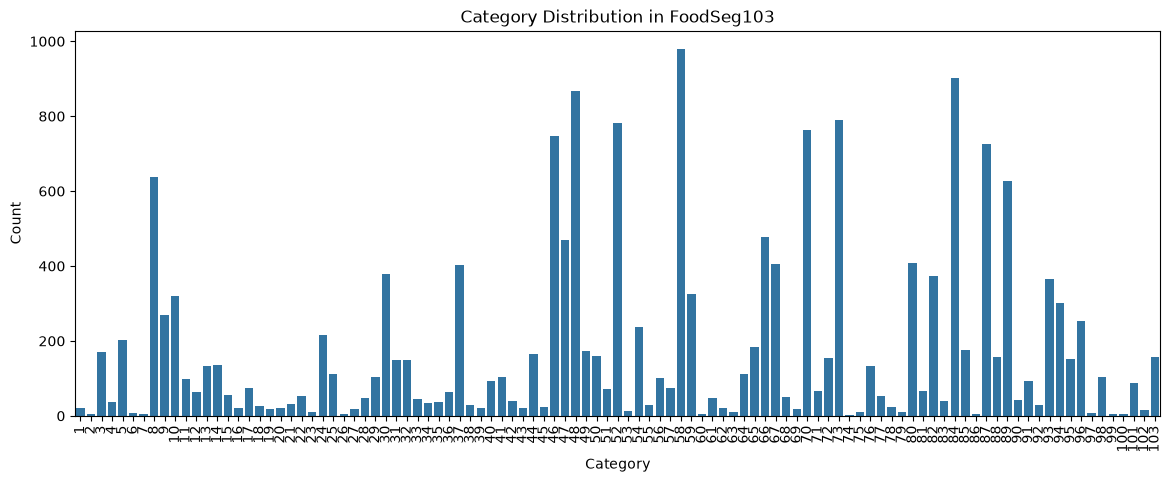

In [5]:
cwd = Path.cwd()
dataset_candidates = [
    base / relative
    for base in (cwd, *cwd.parents)
    for relative in (
        Path("dataset/foodseg103/Images"),
        Path("dataset/FoodSeg103/Images"),
        Path("FoodSeg103/Images"),
        Path("foodseg103/Images"),
    )
]

images_root = next(
    (
        path for path in dataset_candidates
        if (path / "img_dir/train").is_dir()
        and (path / "ann_dir/train").is_dir()
    ),
    None,
)

if images_root is None:
    raise FileNotFoundError(
        f"Could not find FoodSeg103 image and annotation folders. "
        f"Notebook working directory: {cwd}. "
        "Check that the dataset is downloaded/extracted and update the dataset path."
    )

img_dir = images_root / "img_dir/train"
ann_dir = images_root / "ann_dir/train"

img_files = sorted(
    p.name for p in img_dir.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
)
ann_files = sorted(
    p.name for p in ann_dir.iterdir()
    if p.suffix.lower() == ".png"
)

print(f"Number of images: {len(img_files)}")
print(f"Number of annotations: {len(ann_files)}")

category_counts = {}

for ann_file in ann_files:
    ann_path = ann_dir / ann_file
    ann_array = np.array(Image.open(ann_path))
    for category in np.unique(ann_array):
        if category != 0:  # Ignore background
            category_counts[category] = category_counts.get(category, 0) + 1

plt.figure(figsize=(14, 5))
sns.barplot(x=list(category_counts.keys()), y=list(category_counts.values()))
plt.xlabel("Category")
plt.ylabel("Count")
plt.title("Category Distribution in FoodSeg103")
plt.xticks(rotation=90)
plt.show()

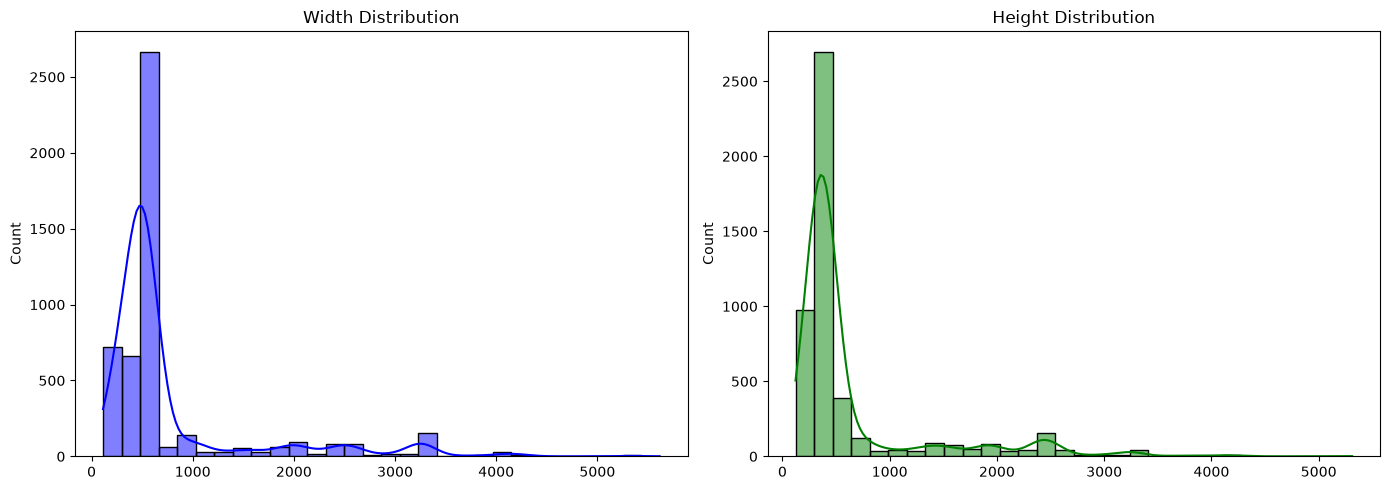

Max width: 5616
Max height: 5312
Min width: 113
Min height: 122


In [ ]:
# image size analysis
image_sizes = []

for img_file in img_files:
    img_path = os.path.join(img_dir, img_file)
    img = Image.open(img_path)
    img_width, img_height = img.size
    image_sizes.append((img_width, img_height))

"""Extract widths and heights from image sizes."""
widths, heights = zip(*image_sizes)
max_width = max(widths)
max_height = max(heights)

"""Plot the image size distribution."""
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
sns.histplot(widths, kde=True, bins=30, color='blue')
plt.title('Width Distribution')

"""Plot the height distribution."""
plt.subplot(1, 2, 2)
sns.histplot(heights, kde=True, bins=30, color='green')
plt.title('Height Distribution')

"""Print the summary statistics for image sizes."""
plt.tight_layout()
plt.show()
print(f"Max width: {max_width}")
print(f"Max height: {max_height}")
print(f"Min width: {min(widths)}")
print(f"Min height: {min(heights)}")


Matched pairs: 4983


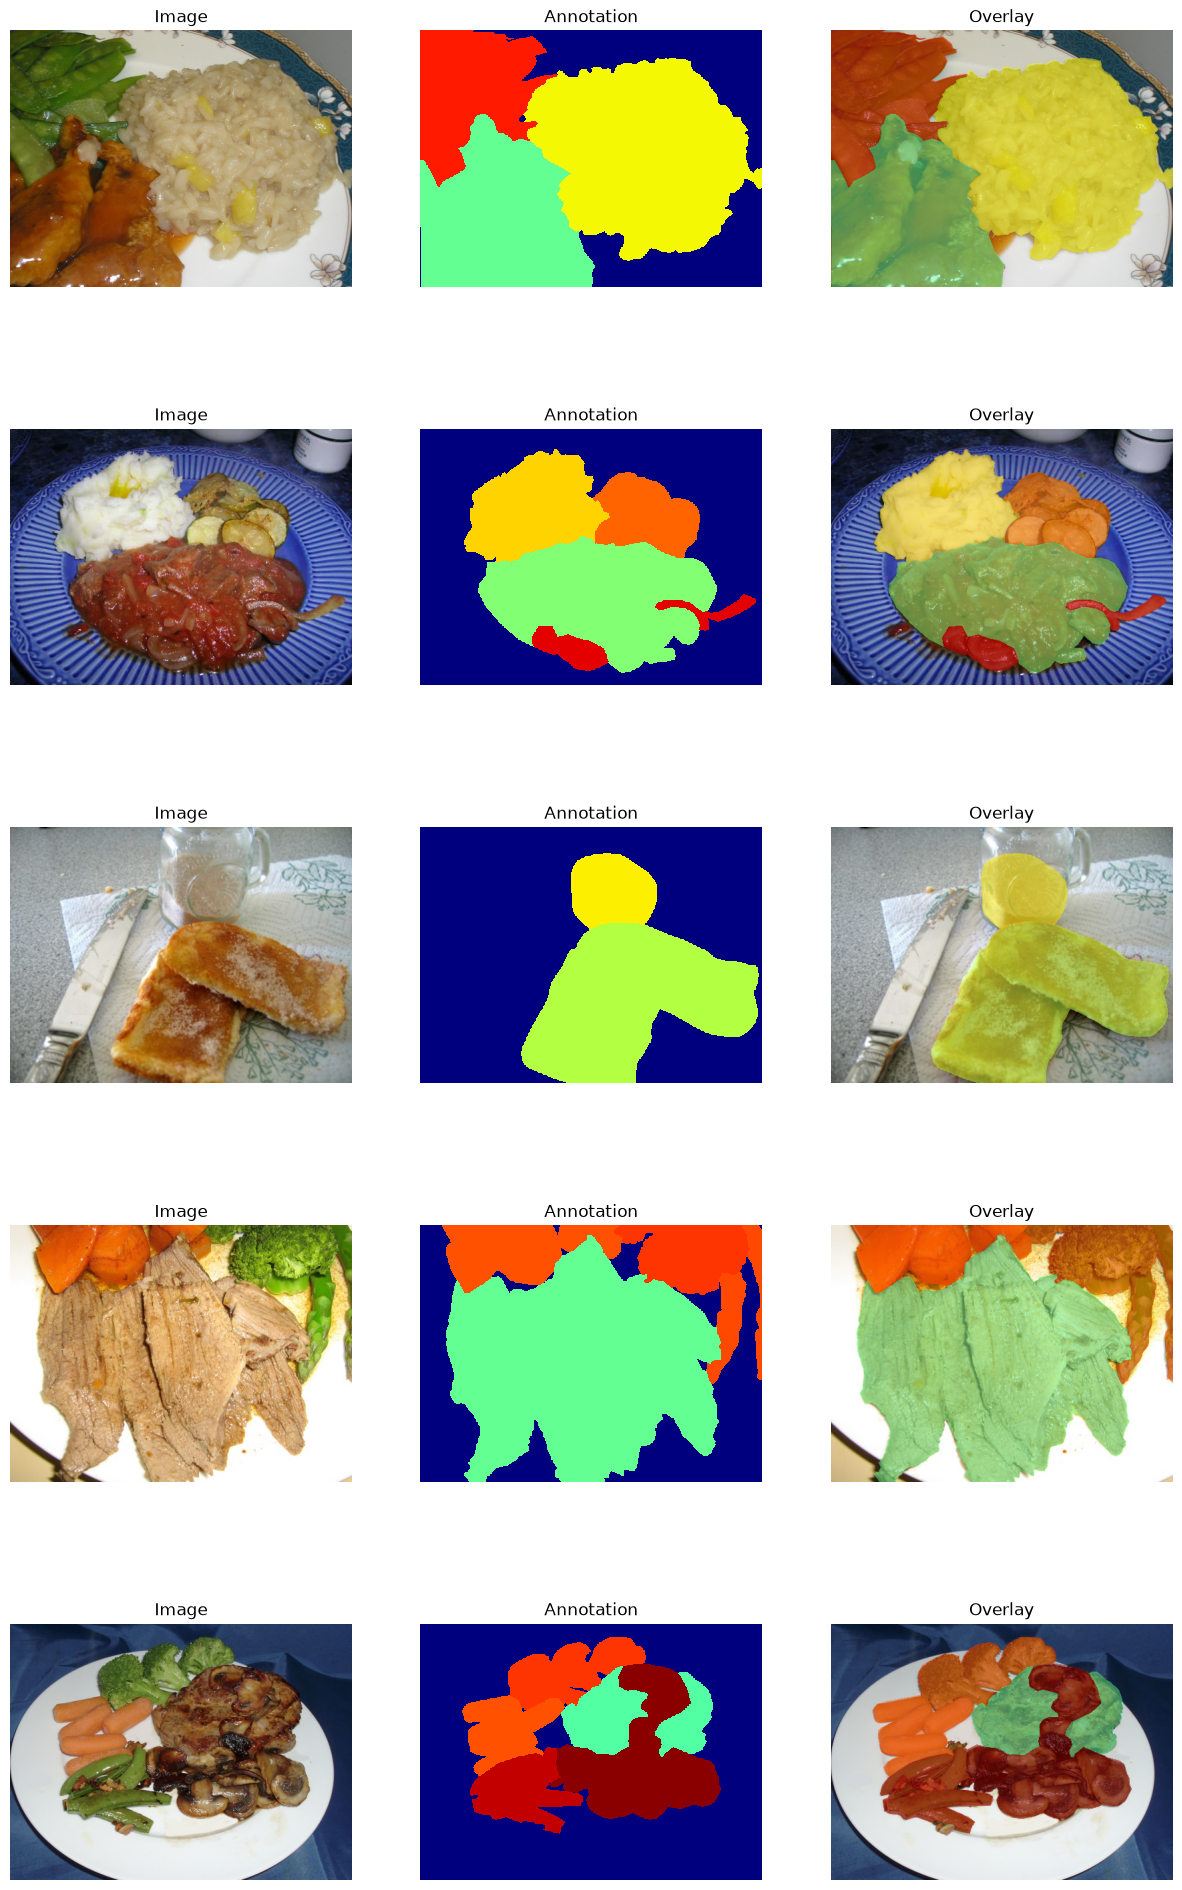

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from glob import glob
from matplotlib.colors import ListedColormap, BoundaryNorm

"""Build matching image/annotation pairs by filename stem from selected split dirs."""
image_by_stem = {
    os.path.splitext(name)[0]: os.path.join(img_dir, name)
    for name in os.listdir(img_dir)
    if name.lower().endswith((".jpg", ".jpeg", ".png"))
}
ann_by_stem = {
    os.path.splitext(os.path.basename(p))[0]: p
    for p in sorted(glob(os.path.join(ann_dir, "*.png")))
}

"""Find common stems between images and annotations."""
common_stems = sorted(image_by_stem.keys() & ann_by_stem.keys())
"""Collect the image and annotation paths for the common stems."""
image_paths = [image_by_stem[stem] for stem in common_stems]
"""Collect the annotation paths for the common stems."""
ann_paths = [ann_by_stem[stem] for stem in common_stems]

"""Custom colormap excluding background."""
num_classes = 103
colors = plt.get_cmap('jet', num_classes)
cmap = ListedColormap(colors(np.linspace(0, 1, num_classes)))
norm = BoundaryNorm(np.arange(num_classes + 1) - 0.5, num_classes)

"""Load and overlay image with annotation."""
def load_and_overlay_image(image_path, ann_path):
    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    annotation = np.array(Image.open(ann_path))

    mask = annotation != 0
    color_mapped_ann = cmap(norm(annotation))[:, :, :3]

    overlay = image.copy()
    overlay[mask] = (overlay[mask] * 0.5 + color_mapped_ann[mask] * 255 * 0.5).astype(np.uint8)
    return image, annotation, overlay

"""Display sample images with their annotations and overlays."""
def display_samples(image_paths, ann_paths, num_samples=5):
    plt.figure(figsize=(15, num_samples * 5))
    for i in range(num_samples):
        image, annotation, overlay = load_and_overlay_image(image_paths[i], ann_paths[i])

        plt.subplot(num_samples, 3, i * 3 + 1)
        plt.imshow(image)
        plt.title("Image")
        plt.axis('off')

        plt.subplot(num_samples, 3, i * 3 + 2)
        plt.imshow(annotation, cmap=cmap, norm=norm, interpolation='nearest')
        plt.title("Annotation")
        plt.axis('off')

        plt.subplot(num_samples, 3, i * 3 + 3)
        plt.imshow(overlay)
        plt.title("Overlay")
        plt.axis('off')

    plt.show()

"""Display matched image and annotation pairs."""
if common_stems:
    print(f'Matched pairs: {len(common_stems)}')
    display_samples(image_paths, ann_paths, num_samples=min(5, len(common_stems)))
else:
    print('No matching image and annotation files found. Check img_dir and ann_dir.')